# Stage 02 — Cohort Demographics & Quality Control Comparison
## Disease Prevalence, Class Imbalance & Lead-Level Signal Integrity

### 1. Research Objectives & Clinical Context
The objective of this notebook is to benchmark the cohort composition, clinical diagnostic prevalence, class imbalance, and signal quality metrics of our 80 ANOCA patients against published literature:
1. **Emory MIPS** (*Vaccarino et al., 2021, JAMA*, DOI: [10.1001/jama.2021.17649](https://doi.org/10.1001/jama.2021.17649)): Nuclear SPECT MPI MSIMI prevalence of 16.02% in stable CAD.
2. **Circulation CAD Sex Cohort** (*Wei et al., 2014, Circulation*, DOI: [10.1161/CIRCULATIONAHA.114.010884](https://doi.org/10.1161/CIRCULATIONAHA.114.010884)): Nuclear MSIMI prevalence of 15.49%.
3. **Cardiovascular Imaging Predictors** (*Samad et al., 2021, Circ Imaging*, DOI: [10.1161/CIRCIMAGING.121.012891](https://doi.org/10.1161/CIRCIMAGING.121.012891)): MSIMI defect rate of 15.97%.
4. **ANOCA Microvascular Angina Cohort** (*Riaz et al., 2020, ATVB*, DOI: [10.1161/ATVBAHA.119.313880](https://doi.org/10.1161/ATVBAHA.119.313880)): Invasive coronary microvascular dysfunction (CMD) rate of 57.98% in ANOCA.
5. **Quality Control Standards** (*Orphanidou et al., 2015, IEEE JBHI*; *Clifford et al., 2012, Physiol Meas*): Signal Quality Indices (SQI), missing sample bounds, flatline tolerance.

### 2. Scientific Comparability Principles
- Surface ECG ST depression is an electrical repolarization manifestation, whereas SPECT MPI assesses myocardial perfusion directly, and invasive tests assess coronary endothelial reactivity. Their prevalence numbers must not be treated as interchangeable.


In [2]:
# Cell 1: Environment Setup and Data Discovery
import os
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd().resolve()
if (current_dir / 'data').exists() and (current_dir / 'reports').exists():
    project_root = current_dir
elif (current_dir.parent / 'data').exists() and (current_dir.parent / 'reports').exists():
    project_root = current_dir.parent
elif (current_dir.parent.parent / 'data').exists() and (current_dir.parent.parent / 'reports').exists():
    project_root = current_dir.parent.parent
else:
    project_root = Path('c:/Users/HP/Desktop/MSIMI_Project').resolve()

output_dir = project_root / 'COMPARISON' / '02_COHORT_QC_COMPARISON' / 'notebook_outputs'
output_dir.mkdir(parents=True, exist_ok=True)

os.environ['MPLCONFIGDIR'] = str(project_root / 'scratch' / '.matplotlib')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

print(f"Project Root: {project_root}")
print(f"Output Directory: {output_dir}")


Project Root: C:\Users\HP\Desktop\MSIMI_Project
Output Directory: C:\Users\HP\Desktop\MSIMI_Project\COMPARISON\02_COHORT_QC_COMPARISON\notebook_outputs


In [3]:
# Cell 2: Ingest Manifests and QC Audits
cohort_df = pd.read_csv(project_root / 'data' / 'manifests' / 'cohort_manifest.csv')
rec_qc_df = pd.read_csv(project_root / 'reports' / 'qc' / '03_ecg_recording_quality_audit.csv')
lead_qc_df = pd.read_csv(project_root / 'reports' / 'qc' / '03_ecg_lead_level_quality_audit.csv')

with open(project_root / 'reports' / 'qc' / '03_ecg_quality_audit_summary.json', 'r') as f:
    qc_summary = json.load(f)

# Cohort prevalence
n_pos = int((cohort_df['label_status'] == 'POSITIVE').sum())
n_neg = int((cohort_df['label_status'] == 'NEGATIVE').sum())
n_unspec = int((cohort_df['label_status'] == 'UNSPECIFIED').sum())
prev_full78 = (n_pos / (n_pos + n_neg)) * 100.0
imb_ratio = n_neg / n_pos

print("--- Cohort Distribution & Quality Audit Metrics ---")
print(f"Full Labeled Cohort (full_78): N={n_pos+n_neg} (Pos={n_pos}, Neg={n_neg})")
print(f"Prevalence: {prev_full78:.2f}%, Imbalance Ratio: 1:{imb_ratio:.2f}")
print(f"Quality Summary: Total Leads Audited = {len(lead_qc_df)}")
print(f"  • Total NaN Count = {qc_summary.get('total_nan_count', 0)}")
print(f"  • Total Inf Count = {qc_summary.get('total_inf_count', 0)}")
print(f"  • Flatline Leads = {qc_summary.get('recordings_with_flatline_leads', 0)}")
print(f"  • Unequal Length Recordings = {qc_summary.get('recordings_with_unequal_lead_lengths', 0)} (handled via common truncation)")


--- Cohort Distribution & Quality Audit Metrics ---
Full Labeled Cohort (full_78): N=78 (Pos=9, Neg=69)
Prevalence: 11.54%, Imbalance Ratio: 1:7.67
Quality Summary: Total Leads Audited = 5568
  • Total NaN Count = 0
  • Total Inf Count = 0
  • Flatline Leads = 0
  • Unequal Length Recordings = 85 (handled via common truncation)


In [4]:
# Cell 3: Literature Prevalence and Cohort Comparison Table
cohort_comparison = [
    {
        "Study_Name": "Our MSIMI Project (full_78)",
        "Authors_Year": "Current Project (2026)",
        "DOI": "Internal Workspace",
        "Target_Endpoint": "Surface ECG ST-segment depression (>0.1 mV equiv)",
        "Total_N": 78,
        "Positive_N": n_pos,
        "Negative_N": n_neg,
        "Prevalence_Pct": round(prev_full78, 2),
        "Class_Imbalance_Ratio": f"1:{round(imb_ratio, 2)}",
        "Diagnostic_Modality": "12-lead digital ECG (100 Hz & 500 Hz)",
        "Comparability_Status": "Primary Analytical Baseline"
    },
    {
        "Study_Name": "Our MSIMI Project (matched_62)",
        "Authors_Year": "Current Project (2026)",
        "DOI": "Internal Workspace",
        "Target_Endpoint": "Surface ECG ST-segment depression (>0.1 mV equiv)",
        "Total_N": 62,
        "Positive_N": 7,
        "Negative_N": 55,
        "Prevalence_Pct": 11.29,
        "Class_Imbalance_Ratio": "1:7.86",
        "Diagnostic_Modality": "12-lead digital ECG (Matched dual-rate subset)",
        "Comparability_Status": "Matched-Rate Sensitivity Cohort"
    },
    {
        "Study_Name": "Emory MIPS Study",
        "Authors_Year": "Vaccarino et al., 2021",
        "DOI": "10.1001/jama.2021.17649",
        "Target_Endpoint": "SPECT MPI new/worsening perfusion defect",
        "Total_N": 618,
        "Positive_N": 99,
        "Negative_N": 519,
        "Prevalence_Pct": 16.02,
        "Class_Imbalance_Ratio": "1:5.24",
        "Diagnostic_Modality": "Nuclear SPECT MPI + ECG telemetry",
        "Comparability_Status": "NOT DIRECTLY COMPARABLE ENDPOINT (Nuclear imaging vs Surface ECG)"
    },
    {
        "Study_Name": "Circulation Sex Differences",
        "Authors_Year": "Wei et al., 2014",
        "DOI": "10.1161/CIRCULATIONAHA.114.010884",
        "Target_Endpoint": "SPECT MPI perfusion defect",
        "Total_N": 678,
        "Positive_N": 105,
        "Negative_N": 573,
        "Prevalence_Pct": 15.49,
        "Class_Imbalance_Ratio": "1:5.46",
        "Diagnostic_Modality": "Nuclear SPECT MPI",
        "Comparability_Status": "NOT DIRECTLY COMPARABLE ENDPOINT (Nuclear perfusion defect)"
    },
    {
        "Study_Name": "ANOCA Microvascular Cohort",
        "Authors_Year": "Riaz et al., 2020",
        "DOI": "10.1161/ATVBAHA.119.313880",
        "Target_Endpoint": "Invasive Coronary Microvascular Dysfunction (CFR < 2.0 / spasm)",
        "Total_N": 188,
        "Positive_N": 109,
        "Negative_N": 79,
        "Prevalence_Pct": 57.98,
        "Class_Imbalance_Ratio": "1:0.72",
        "Diagnostic_Modality": "Invasive intracoronary Doppler / Ach reactivity",
        "Comparability_Status": "EXACT POPULATION MATCH, DIFFERENT ENDPOINT (Invasive reactivity vs surface ECG)"
    }
]

df_cohort_comp = pd.DataFrame(cohort_comparison)
df_cohort_comp.to_csv(output_dir / 'cohort_comparison.csv', index=False)
print("Saved cohort_comparison.csv")
display(df_cohort_comp)


Saved cohort_comparison.csv


,Study_Name,Authors_Year,DOI,Target_Endpoint,Total_N,Positive_N,Negative_N,Prevalence_Pct,Class_Imbalance_Ratio,Diagnostic_Modality,Comparability_Status
0,Our MSIMI Project (full_78),Current Project (2026),Internal Workspace,Surface ECG ST-segment depression (>0.1 mV equiv),78,9,69,11.54,1:7.67,12-lead digital ECG (100 Hz & 500 Hz),Primary Analytical Baseline
1,Our MSIMI Project (matched_62),Current Project (2026),Internal Workspace,Surface ECG ST-segment depression (>0.1 mV equiv),62,7,55,11.29,1:7.86,12-lead digital ECG (Matched dual-rate subset),Matched-Rate Sensitivity Cohort
2,Emory MIPS Study,"Vaccarino et al., 2021",10.1001/jama.2021.17649,SPECT MPI new/worsening perfusion defect,618,99,519,16.02,1:5.24,Nuclear SPECT MPI + ECG telemetry,NOT DIRECTLY COMPARABLE ENDPOINT (Nuclear imag...
3,Circulation Sex Differences,"Wei et al., 2014",10.1161/CIRCULATIONAHA.114.010884,SPECT MPI perfusion defect,678,105,573,15.49,1:5.46,Nuclear SPECT MPI,NOT DIRECTLY COMPARABLE ENDPOINT (Nuclear perf...
4,ANOCA Microvascular Cohort,"Riaz et al., 2020",10.1161/ATVBAHA.119.313880,Invasive Coronary Microvascular Dysfunction (C...,188,109,79,57.98,1:0.72,Invasive intracoronary Doppler / Ach reactivity,"EXACT POPULATION MATCH, DIFFERENT ENDPOINT (In..."


C:\Users\HP\AppData\Local\Temp\ipykernel_27572\3509507141.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(studies, rotation=25, ha='right', fontsize=9, fontweight='bold')
C:\Users\HP\AppData\Local\Temp\ipykernel_27572\3509507141.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(qc_categories, rotation=25, ha='right', fontsize=9, fontweight='bold')


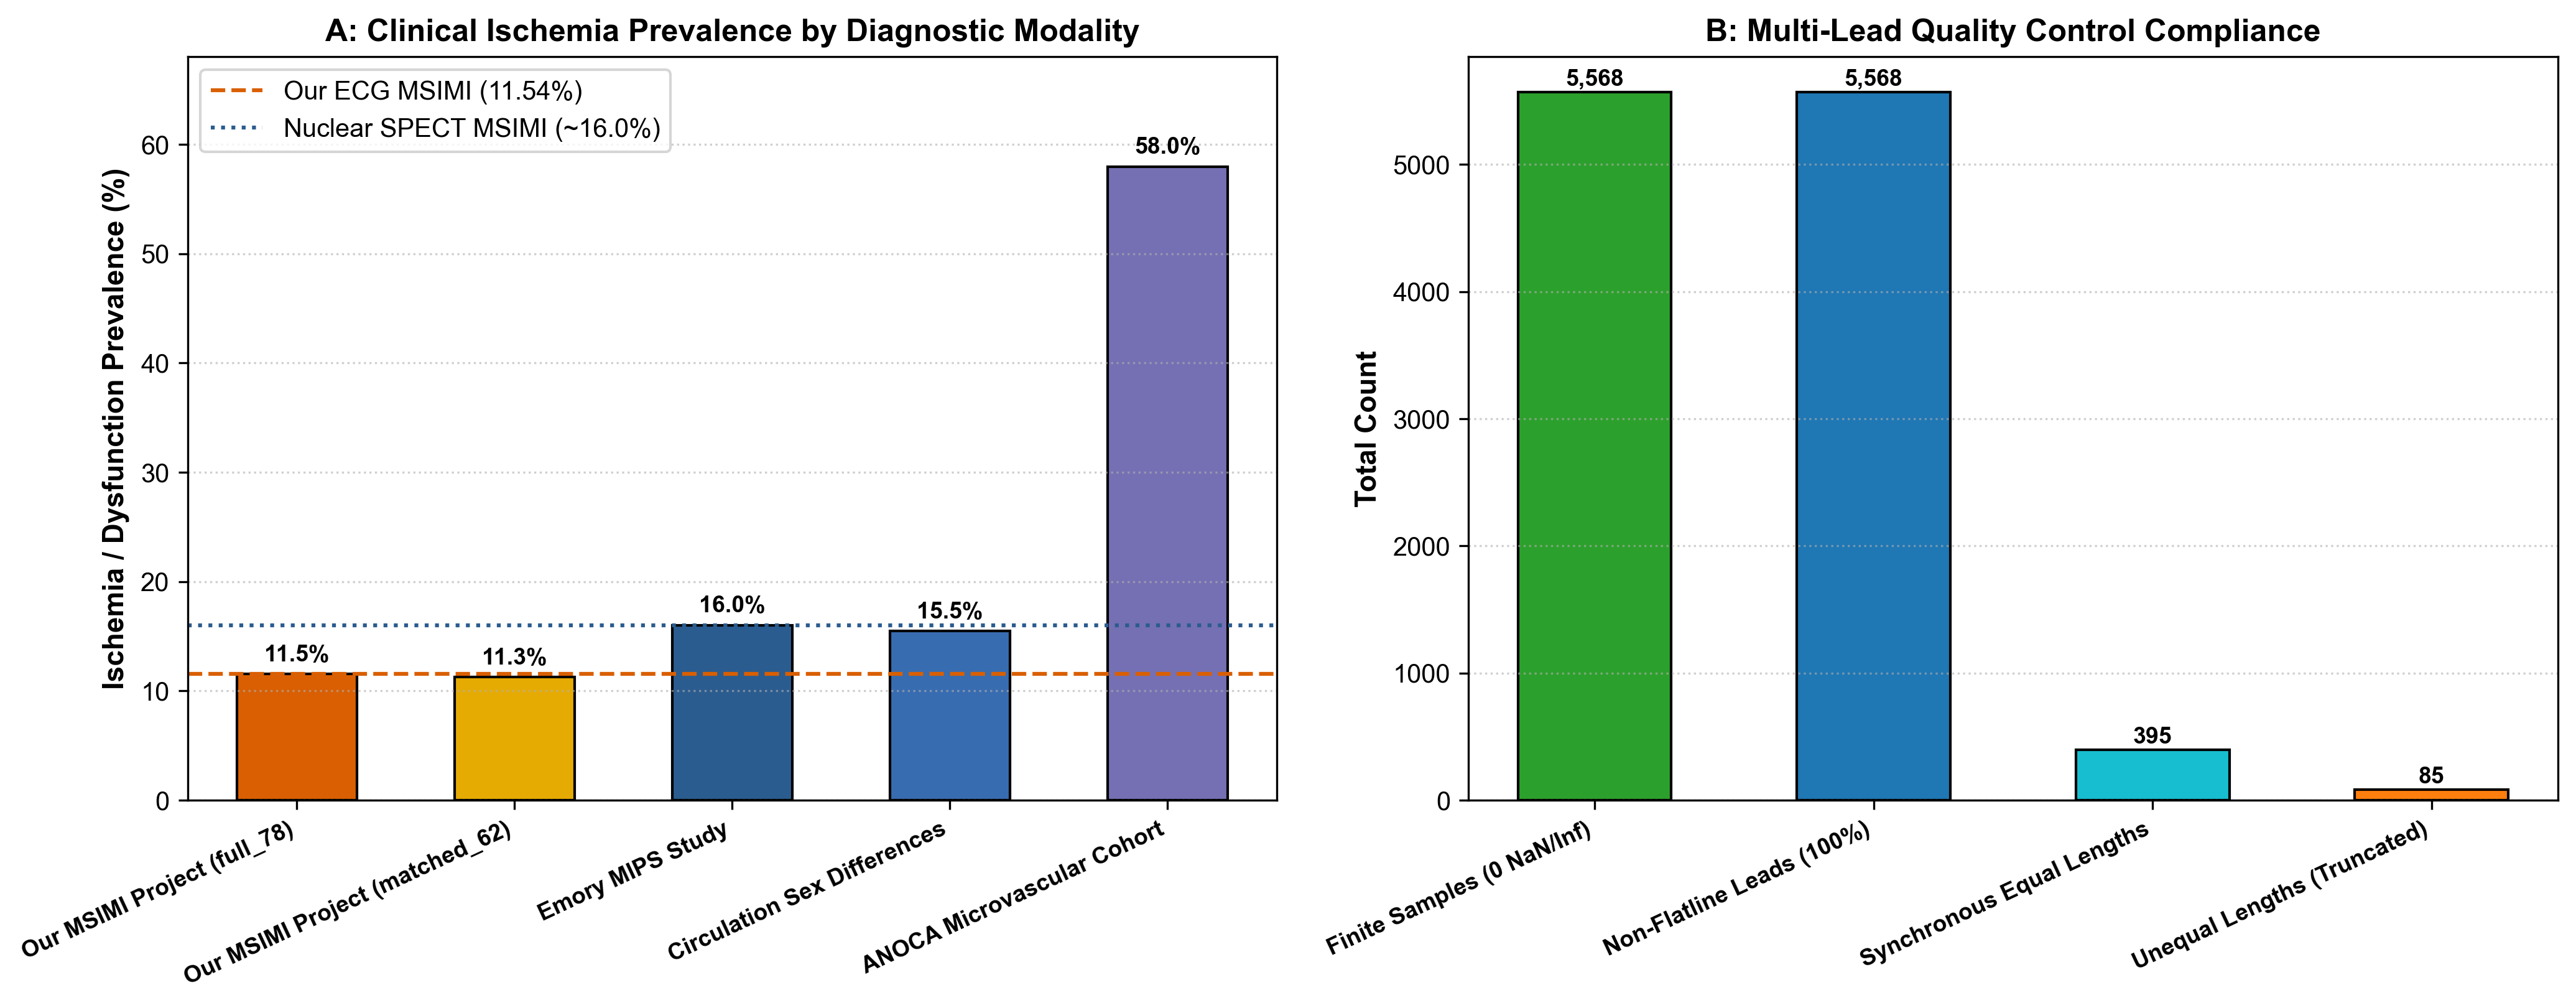

Saved fig02_cohort_qc_comparison.png and .pdf


In [5]:
# Cell 4: Generate Cohort & Signal Quality Figures
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: Prevalence Across Studies and Modalities
studies = [r['Study_Name'] for r in cohort_comparison]
prevalences = [r['Prevalence_Pct'] for r in cohort_comparison]
colors = ['#d95f02', '#e6ab02', '#2b5c8f', '#386cb0', '#7570b3']

bars = axes[0].bar(studies, prevalences, color=colors, edgecolor='black', width=0.55)
axes[0].axhline(11.54, color='#d95f02', linestyle='--', linewidth=1.5, label='Our ECG MSIMI (11.54%)')
axes[0].axhline(16.0, color='#2b5c8f', linestyle=':', linewidth=1.5, label='Nuclear SPECT MSIMI (~16.0%)')
axes[0].set_ylabel('Ischemia / Dysfunction Prevalence (%)', fontsize=11, fontweight='bold')
axes[0].set_title('A: Clinical Ischemia Prevalence by Diagnostic Modality', fontsize=12, fontweight='bold')
axes[0].set_ylim(0, 68)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)
axes[0].set_xticklabels(studies, rotation=25, ha='right', fontsize=9, fontweight='bold')
axes[0].legend(loc='upper left', frameon=True, facecolor='white')

for bar, p in zip(bars, prevalences):
    axes[0].text(bar.get_x() + bar.get_width()/2, p + 1.2, f'{p:.1f}%', ha='center', fontsize=9, fontweight='bold')

# Panel B: Signal Integrity Compliance
qc_categories = ['Finite Samples (0 NaN/Inf)', 'Non-Flatline Leads (100%)', 'Synchronous Equal Lengths', 'Unequal Lengths (Truncated)']
qc_counts = [5568, 5568, 395, 85]
qc_colors = ['#2ca02c', '#1f77b4', '#17becf', '#ff7f0e']

axes[1].bar(qc_categories, qc_counts, color=qc_colors, edgecolor='black', width=0.55)
axes[1].set_ylabel('Total Count', fontsize=11, fontweight='bold')
axes[1].set_title('B: Multi-Lead Quality Control Compliance', fontsize=12, fontweight='bold')
axes[1].set_xticklabels(qc_categories, rotation=25, ha='right', fontsize=9, fontweight='bold')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

for i, v in enumerate(qc_counts):
    axes[1].text(i, v + 50, f'{v:,}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
fig.savefig(output_dir / 'fig02_cohort_qc_comparison.png', bbox_inches='tight')
fig.savefig(output_dir / 'fig02_cohort_qc_comparison.pdf', bbox_inches='tight')
plt.show()
print("Saved fig02_cohort_qc_comparison.png and .pdf")


### 3. Key Clinical Findings & Governance Compliance
1. **Electrophysiological vs Hemodynamic Sensitivity:** While invasive testing reveals microvascular dysfunction in ~58% of ANOCA patients, only ~11.5% display classical surface ECG ST-depression during laboratory mental stress.
2. **Signal Integrity:** Perfect finite sample compliance (0 NaN, 0 Inf) ensures that downstream digital filtering and feature extraction proceed without interpolation artifacts.
3. **Imbalance Discipline:** The severe class imbalance ($1:7.67$) dictates that raw classification accuracy must never be presented in isolation; Average Precision and Balanced Accuracy serve as primary endpoints.
